In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
    else "cpu"
)
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 15 
LEARNING_RATE = 0.0002

Path("checkpoints").mkdir(exist_ok=True)
Path("samples").mkdir(exist_ok=True)
print("Device:", DEVICE)

Device: mps


In [2]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(LATENT_DIM, 7 * 7 * 128)
        self.conv_layers = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, noise):
        x = self.fc(noise)
        x = x.view(noise.size(0), 128, 7, 7)
        return self.conv_layers(x)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, images):
        return self.layers(images)


generator = Generator().to(DEVICE)
discriminator = Discriminator().to(DEVICE)
print(generator)
print(discriminator)

Generator(
  (fc): Linear(in_features=100, out_features=6272, bias=True)
  (conv_layers): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): Tanh()
  )
)
Discriminator(
  (layers): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Linear(in_features=6272, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


In [3]:
generator.eval()
discriminator.eval()
with torch.no_grad():
    test_noise = torch.randn(8, LATENT_DIM, device=DEVICE)
    test_images = generator(test_noise)
    test_scores = discriminator(test_images)
print("Noise:", tuple(test_noise.shape))
print("Generated images:", tuple(test_images.shape))
print("Discriminator predictions:", tuple(test_scores.shape))
assert test_images.shape == (8, 1, 28, 28)
assert test_scores.shape == (8, 1)
assert ((test_scores >= 0) & (test_scores <= 1)).all()
print("Architecture shape checks passed.")

Noise: (8, 100)
Generated images: (8, 1, 28, 28)
Discriminator predictions: (8, 1)
Architecture shape checks passed.


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 2.25MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.03MB/s]


MNIST training images: 60000
Batch shape: (128, 1, 28, 28)


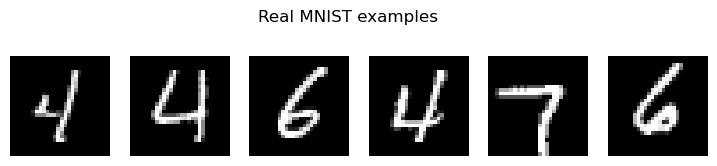

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

mnist = datasets.MNIST(
    root="./data", train=True, transform=transform, download=True
)
train_loader = DataLoader(
    mnist, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
print("MNIST training images:", len(mnist))
real_batch, labels = next(iter(train_loader))
print("Batch shape:", tuple(real_batch.shape))

fig, axs = plt.subplots(1, 6, figsize=(9, 2))
for idx, ax in enumerate(axs):
    ax.imshow(real_batch[idx, 0].numpy(), cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
plt.suptitle("Real MNIST examples")
plt.show()

In [5]:
generator = Generator().to(DEVICE)
discriminator = Discriminator().to(DEVICE)

criterion = nn.BCELoss()
optimizer_g = torch.optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
fixed_noise = torch.randn(16, LATENT_DIM, device=DEVICE)
g_losses, d_losses = [], []

In [6]:
for epoch in range(1, EPOCHS + 1):
    generator.train()
    discriminator.train()
    epoch_g, epoch_d, batches = 0.0, 0.0, 0

    for real_images, _ in train_loader:
        real_images = real_images.to(DEVICE)
        batch_size = real_images.size(0)
        real_targets = torch.ones(batch_size, 1, device=DEVICE)
        fake_targets = torch.zeros(batch_size, 1, device=DEVICE)

        # Train the discriminator using real and fake images.
        optimizer_d.zero_grad(set_to_none=True)
        real_prob = discriminator(real_images)
        noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        fake_images = generator(noise)
        fake_prob = discriminator(fake_images.detach())
        d_loss = 0.5 * (
            criterion(real_prob, real_targets) +
            criterion(fake_prob, fake_targets)
        )
        d_loss.backward()
        optimizer_d.step()

        # Train the generator: make generated images appear real.
        optimizer_g.zero_grad(set_to_none=True)
        for param in discriminator.parameters():
            param.requires_grad_(False)
        predicted_real = discriminator(fake_images)
        g_loss = criterion(predicted_real, real_targets)
        g_loss.backward()
        optimizer_g.step()
        for param in discriminator.parameters():
            param.requires_grad_(True)

        epoch_g += g_loss.item()
        epoch_d += d_loss.item()
        batches += 1

    avg_g, avg_d = epoch_g / batches, epoch_d / batches
    g_losses.append(avg_g)
    d_losses.append(avg_d)

    torch.save(generator.state_dict(), "checkpoints/generator.pt")
    torch.save(discriminator.state_dict(), "checkpoints/discriminator.pt")
    generator.eval()
    with torch.no_grad():
        images = (generator(fixed_noise).cpu() + 1) / 2
        save_image(images.clamp(0, 1), f"samples/epoch_{epoch:03d}.png", nrow=4)
    print(f"Epoch {epoch}/{EPOCHS} | G Loss: {avg_g:.4f} | D Loss: {avg_d:.4f}")

print("Training complete. Weights saved in checkpoints/.")

Epoch 1/15 | G Loss: 2.2955 | D Loss: 0.2003
Epoch 2/15 | G Loss: 2.4052 | D Loss: 0.1705
Epoch 3/15 | G Loss: 2.4946 | D Loss: 0.1795
Epoch 4/15 | G Loss: 2.3999 | D Loss: 0.1920
Epoch 5/15 | G Loss: 2.3827 | D Loss: 0.1992
Epoch 6/15 | G Loss: 2.4013 | D Loss: 0.2045
Epoch 7/15 | G Loss: 2.5167 | D Loss: 0.1859
Epoch 8/15 | G Loss: 2.5168 | D Loss: 0.1962
Epoch 9/15 | G Loss: 2.6652 | D Loss: 0.1755
Epoch 10/15 | G Loss: 2.6683 | D Loss: 0.1869
Epoch 11/15 | G Loss: 2.8297 | D Loss: 0.1774
Epoch 12/15 | G Loss: 2.8626 | D Loss: 0.1540
Epoch 13/15 | G Loss: 3.0285 | D Loss: 0.1456
Epoch 14/15 | G Loss: 2.9518 | D Loss: 0.1705
Epoch 15/15 | G Loss: 3.1797 | D Loss: 0.1340
Training complete. Weights saved in checkpoints/.


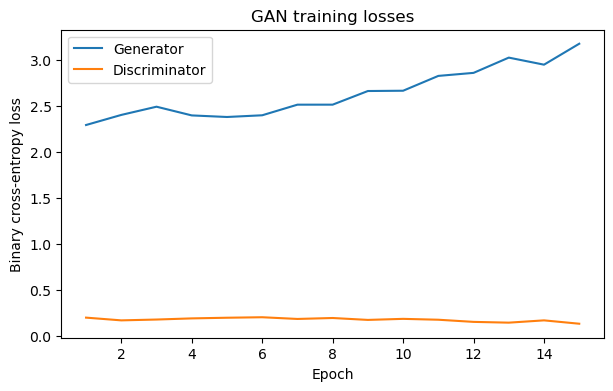

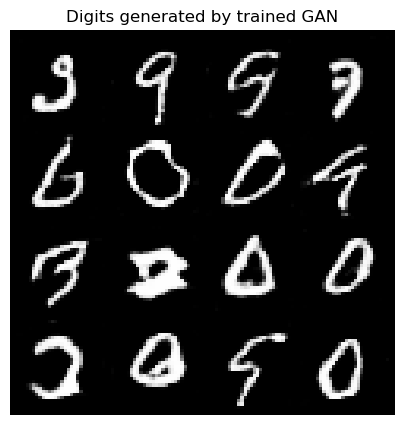

Saved: samples/final_generated_digits.png


In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(g_losses)+1), g_losses, label="Generator")
plt.plot(range(1, len(d_losses)+1), d_losses, label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("GAN training losses")
plt.legend()
plt.show()

# Load the trained generator for inference.
generator = Generator().to(DEVICE)
generator.load_state_dict(
    torch.load("checkpoints/generator.pt", map_location=DEVICE, weights_only=True)
)
generator.eval()
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, device=DEVICE)
    samples = ((generator(z).cpu() + 1) / 2).clamp(0, 1)

grid = make_grid(samples, nrow=4, padding=2)
plt.figure(figsize=(5, 5))
plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
plt.axis("off")
plt.title("Digits generated by trained GAN")
plt.show()
save_image(samples, "samples/final_generated_digits.png", nrow=4)
print("Saved: samples/final_generated_digits.png")

In [8]:
from pathlib import Path

model_source = '''import torch
from torch import nn

LATENT_DIM = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(LATENT_DIM, 7 * 7 * 128)
        self.conv_layers = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise):
        x = self.fc(noise)
        x = x.view(noise.size(0), 128, 7, 7)
        return self.conv_layers(x)
'''

Path("gan_model.py").write_text(
    model_source, encoding="utf-8"
)


# 2. Create the GAN API router
api_source = '''import io
from pathlib import Path

import torch
from fastapi import APIRouter, HTTPException, Query
from fastapi.responses import Response
from PIL import Image
from torchvision.utils import make_grid

from gan_model import Generator, LATENT_DIM

router = APIRouter(prefix="/gan", tags=["GAN"])

WEIGHTS_PATH = (
    Path(__file__).resolve().parent
    / "checkpoints" / "generator.pt"
)


@router.get("/status")
def status():
    return {
        "model": "MNIST GAN",
        "weights_available": WEIGHTS_PATH.exists()
    }


@router.get("/generate")
def generate(count: int = Query(default=4, ge=1, le=16)):
    if not WEIGHTS_PATH.is_file():
        raise HTTPException(
            status_code=503,
            detail="Train your GAN first to create generator.pt"
        )

    generator = Generator().to("cpu")

    generator.load_state_dict(
        torch.load(
            WEIGHTS_PATH,
            map_location="cpu",
            weights_only=True
        )
    )

    generator.eval()

    with torch.no_grad():
        noise = torch.randn(count, LATENT_DIM)
        images = (generator(noise) + 1) / 2

        grid = make_grid(
            images.clamp(0, 1),
            nrow=min(count, 4)
        )

    array = (
        grid.permute(1, 2, 0).numpy() * 255
    ).round().astype("uint8")

    output = io.BytesIO()

    Image.fromarray(array, mode="RGB").save(
        output,
        format="PNG"
    )

    return Response(
        content=output.getvalue(),
        media_type="image/png"
    )
'''

Path("gan_api.py").write_text(
    api_source, encoding="utf-8"
)


example_source = '''from fastapi import FastAPI
from gan_api import router as gan_router

app = FastAPI(title="Module 6 + MNIST GAN")

app.include_router(gan_router)
'''

Path("api_example.py").write_text(
    example_source, encoding="utf-8"
)

print("Saved gan_model.py")
print("Saved gan_api.py")
print("Saved api_example.py")
print("API files created successfully!")


Saved gan_model.py
Saved gan_api.py
Saved api_example.py
API files created successfully!


In [9]:
from pathlib import Path

model_path = Path("checkpoints/generator.pt")

if model_path.exists():
    print("GAN model is saved successfully!")
    print("Model path:", model_path)
else:
    print("Model not found. Please run the training cell first.")

GAN model is saved successfully!
Model path: checkpoints/generator.pt


In [11]:
%pip install fastapi uvicorn httpx

  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.12.2
    Uninstalling typing_extensions-4.12.2:
      Successfully uninstalled typing_extensions-4.12.2━━━━━━━━━━━ 1/7 [typing-extensions]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [fastapi]m6/7 [fastapi]d-doc]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


API Status Code: 200
API Status: {'model': 'MNIST GAN', 'weights_available': True}
Generate Status Code: 200
GAN API test successful!


/opt/anaconda3/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


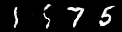

Saved: samples/api_generated_digits.png


In [12]:

# Cell 10 — Test GAN API

from fastapi.testclient import TestClient
from api_example import app
from IPython.display import display, Image
from pathlib import Path

client = TestClient(app)

# Step 1: Check API status
status_response = client.get("/gan/status")

print("API Status Code:", status_response.status_code)
print("API Status:", status_response.json())

# Step 2: Generate handwritten digits
response = client.get("/gan/generate", params={"count": 4})

print("Generate Status Code:", response.status_code)

if response.status_code == 200:
    print("GAN API test successful!")

    # Display generated digits
    display(Image(data=response.content))

    # Save generated image
    Path("samples").mkdir(exist_ok=True)

    Path("samples/api_generated_digits.png").write_bytes(
        response.content
    )

    print("Saved: samples/api_generated_digits.png")

else:
    print("API Error:", response.text)


In [13]:
import os

print("Current directory:", os.getcwd())

print("\nFiles in this directory:")
for file in os.listdir("."):
    print(file)

Current directory: /Users/liuyue

Files in this directory:
Untitled Folder
Untitled10.ipynb
Untitled7.ipynb
.config
Music
.cursor
.bytertc
.condarc
.docker
.copilot
Untitled12.ipynb
Untitled5.ipynb
Untitled1.ipynb
Healthcare FE 2.ipynb
Untitled16.ipynb
.DS_Store
nltk_data
.vscode-shared
gan_api.py
.CFUserTextEncoding
.xonshrc
anaconda_projects
Untitled3.ipynb
Untitled14.ipynb
Untitled.ipynb
.zshrc
未命名0.py
Untitled4.ipynb
.streamlit
.local
Untitled13.ipynb
Untitled6.ipynb
.mongodb
Pictures
Untitled11.ipynb
.zprofile
.ipfs
Assignment3_GAN_Standalone.ipynb
checkpoints
Yue_Liu_PCA_iForest_Assignment.ipynb
Untitled15.ipynb
streamlit_app.py
.zsh_history
Untitled2.ipynb
.ipython
Desktop
Library
.matplotlib
__pycache__
.oracle_jre_usage
WebstormProjects
.spyder-py3
purchase_credit_card.csv (3).zip
5420
.android
.pgadmin
.cups
samples
Healthcare_Feature_Creation_Yue_Liu.ipynb
Module_2_Practical_3_Word_Embeddings-2 (1).ipynb
untitled.txt
5205
api_example.py
capstone
.codex
Public
.cache_remix_id

In [14]:

from pathlib import Path
import os

home = Path.home()

folders = [
    home,
    home / "Desktop",
    home / "Documents",
    home / "Downloads",
    home / "anaconda_projects",
    home / "Untitled Folder"
]

keywords = ["module6", "module_6", "module 6",
            "api", "fastapi", "server"]

found = set()
skip_folders = {
    ".git", "node_modules", "__pycache__",
    ".ipynb_checkpoints", "venv", ".venv",
    "site-packages"
}

for folder in folders:
    if not folder.exists():
        continue

    for root, dirs, files in os.walk(folder):
        depth = len(Path(root).relative_to(folder).parts)

        if depth >= 3 or folder == home:
            dirs[:] = []
        else:
            dirs[:] = [
                d for d in dirs
                if d not in skip_folders and not d.startswith(".")
            ]

        for filename in files:
            name = filename.lower()

            if name in {"gan_api.py", "api_example.py"}:
                continue

            if any(word in name for word in keywords):
                found.add(str(Path(root) / filename))

print("Possible Module 6 API files:\n")

if found:
    for filename in sorted(found)[:40]:
        print(filename)
else:
    print("No matching files found.")


Possible Module 6 API files:

/Users/liuyue/Desktop/5400/APAN5400_F25_Module6.pdf
/Users/liuyue/Desktop/5400/Module6_MongoDB.ipynb
/Users/liuyue/Desktop/job/Cover letter Junson Capital.docx
/Users/liuyue/Desktop/tripflow/public/js/api.js
/Users/liuyue/Desktop/tripflow/server/server.js
/Users/liuyue/Desktop/tripflow_Ella 2/tripflow/server/server.js
/Users/liuyue/Desktop/tripflow_Ella/tripflow/server/server.js
/Users/liuyue/Downloads/APAN 5600 Spring 2026 Module 6.pdf
/Users/liuyue/Downloads/APAN 5800 Module 6 Fall 2025.pdf
/Users/liuyue/Downloads/APAN5490_S26_Module6.pdf
/Users/liuyue/Downloads/Assignment3_GAN_Submission/api.py
/Users/liuyue/Downloads/Assignment3_GAN_Submission/tests/test_api.py
/Users/liuyue/Downloads/F25 Module 6 RJS (1).pdf
/Users/liuyue/Downloads/F25 Module 6 RJS (2).pdf
/Users/liuyue/Downloads/F25 Module 6 RJS.pdf
/Users/liuyue/Downloads/Module 3 Activity - First Docker_FastAPI Project Setup and Simple Text Generator-1 (1).pdf
/Users/liuyue/Downloads/Module 3 Activ

In [15]:

from pathlib import Path
import os

home = Path.home()
folders = [
    home / "Desktop",
    home / "Documents",
    home / "Downloads",
    home / "anaconda_projects"
]

skip = {
    "node_modules", ".git", ".venv", "venv",
    "__pycache__", "site-packages",
    "Assignment3_GAN_Submission"
}

results = []

for base in folders:
    if not base.exists():
        continue

    for root, dirs, files in os.walk(base):
        depth = len(Path(root).relative_to(base).parts)
        dirs[:] = [
            d for d in dirs
            if d not in skip and not d.startswith(".")
            and depth < 4
        ]

        for filename in files:
            if not filename.endswith((".py", ".ipynb")):
                continue
            if "Assignment3_GAN" in filename:
                continue

            path = Path(root) / filename

            try:
                if path.stat().st_size > 2_000_000:
                    continue

                content = path.read_text(
                    encoding="utf-8", errors="ignore"
                )

                if "FastAPI(" in content or "APIRouter(" in content:
                    results.append(str(path))
            except OSError:
                pass

print("Possible FastAPI project files:\n")

if results:
    for path in sorted(set(results))[:50]:
        print(path)
else:
    print("No original FastAPI project found.")


Possible FastAPI project files:

No original FastAPI project found.


In [16]:

import sys

# Download the spaCy English language model
!{sys.executable} -m spacy download en_core_web_lg


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 28.5 MB/s  0:00:12:00:0100:01

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')


In [17]:
import spacy

nlp = spacy.load("en_core_web_lg")
print("spaCy model loaded successfully!")

spaCy model loaded successfully!


In [19]:
%pip install python-multipart


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


GAN Status: 200 {'model': 'MNIST GAN', 'weights_available': True}
GAN Generate: 200


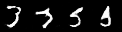

GAN generation test: PASS

=== Full API Integration ===
Original API: 200
Integrated GAN: 200
Integrated GAN generation: 200
FULL API INTEGRATION: PASS


In [20]:

# Step 9 — Test GitHub GAN integration

from pathlib import Path
import sys
from io import BytesIO
from PIL import Image
from IPython.display import display
from fastapi import FastAPI
from fastapi.testclient import TestClient

repo = Path.home() / "Downloads" / "sps_genai_gan_test"
sys.path.insert(0, str(repo))

# Test the uploaded GAN API
from app.gan_api import router as gan_router

test_app = FastAPI()
test_app.include_router(gan_router)
client = TestClient(test_app)

status = client.get("/gan/status")
print("GAN Status:", status.status_code, status.json())

response = client.get("/gan/generate", params={"count": 4})
print("GAN Generate:", response.status_code)

if response.status_code == 200:
    image = Image.open(BytesIO(response.content))
    display(image)
    print("GAN generation test: PASS")
else:
    print("GAN generation error:", response.text)

# Test the original Module 6 API integration
print("\n=== Full API Integration ===")

try:
    from app.main import app as full_app
    full_client = TestClient(full_app)

    root = full_client.get("/")
    print("Original API:", root.status_code)

    gan_status = full_client.get("/gan/status")
    print("Integrated GAN:", gan_status.status_code)

    gan_response = full_client.get(
        "/gan/generate", params={"count": 4}
    )
    print("Integrated GAN generation:", gan_response.status_code)

    if root.status_code == 200 and gan_response.status_code == 200:
        print("FULL API INTEGRATION: PASS")
    else:
        print("FULL API INTEGRATION: NEEDS CHECK")

except Exception as e:
    print("Full API startup needs attention:")
    print(type(e).__name__ + ":", str(e))
